# S2 · Synthetic benchmark with a known posterior

Week 2 tests the theory of `docs/theory.md` where the truth is known exactly: stationary random fields with an exact
covariance, and a voxel-wise tissue-mixture posterior whose marginals are closed-form and whose dependence is set by a
Gaussian copula. Every statement is checked against an explicit criterion; section 7 collects the verdicts.

| Section | Statement |
|---|---|
| 1 | Propositions 1 and 1′: sharp rearrangement bounds; Proposition 2 and Corollary 2.1: at a fixed MAE, range error is governed by error coherence |
| 2 | Propositions 3 and 3.1: range error is low-pass along the beam; all angles weight errors by 1/\|k\| |
| 3 | Propositions 4 and 5: the Bayes act for range is the SPR mean; L1 creates a signed range bias |
| 4 | Theorem 6: only the mean is consistent under projection |
| 5 | Proposition 7: tails of range error need the joint law; the FZ score elicits VaR and ES |
| 6 | Proposition 8: projected CRPS separates dependence structures that voxel-wise CRPS cannot |

Units: 1 voxel = 1 mm along the beam; SPR is dimensionless; range errors are in mm of water.

The notebook runs the code of this repository (`src/`), whether or not the package is installed.

### Setup · install `sctrange` from the repository

Run this cell first. Inside a clone of [hashirama21/sct-range](https://github.com/hashirama21/sct-range) it installs that
clone in editable mode (`pip install -e ".[dose]"`), so the notebook always runs the repository's code, local edits
included. Opened on its own (Colab, another machine), it first downloads the repository from GitHub (no git needed;
`SCTRANGE_REF` selects a branch, tag or commit, default `main`; `SCTRANGE_HOME` the destination), then installs it.
pip only runs when `sctrange` is missing or installed from elsewhere; `SCTRANGE_REINSTALL=1` forces it.

In [1]:
import importlib
import importlib.util
import io
import os
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

REPO_URL = "https://github.com/hashirama21/sct-range"
REPO_REF = os.environ.get("SCTRANGE_REF", "main")


def find_repo(start: Path) -> Path | None:
    return next((p for p in (start, *start.parents) if (p / "pyproject.toml").exists() and (p / "src" / "sctrange").is_dir()),
                None)


def download_repo(destination: Path) -> Path:
    """Fetch ``REPO_REF`` of the GitHub repository as a zip archive and unpack it to ``destination``."""
    with urllib.request.urlopen(f"{REPO_URL}/archive/{REPO_REF}.zip", timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    top = archive.namelist()[0].split("/")[0]
    staging = destination.with_name(destination.name + ".partial")
    shutil.rmtree(staging, ignore_errors=True)
    archive.extractall(staging)
    (staging / top).rename(destination)
    shutil.rmtree(staging, ignore_errors=True)
    return destination


REPO_ROOT = find_repo(Path.cwd())
if REPO_ROOT is None:
    REPO_ROOT = Path(os.environ.get("SCTRANGE_HOME", Path.cwd() / "sct-range")).resolve()
    if find_repo(REPO_ROOT) is None:
        print(f"downloading {REPO_URL} @ {REPO_REF} to {REPO_ROOT}")
        download_repo(REPO_ROOT)
    os.chdir(REPO_ROOT / "notebooks")
SOURCE_DIR = (REPO_ROOT / "src").resolve()


def installed_from_repo() -> bool:
    spec = importlib.util.find_spec("sctrange")
    return spec is not None and spec.origin is not None and Path(spec.origin).resolve().is_relative_to(SOURCE_DIR)


if os.environ.get("SCTRANGE_REINSTALL") == "1" or not installed_from_repo():
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--editable", f"{REPO_ROOT}[dose]"], check=True)
# an editable install is only picked up by new processes; make it visible to this kernel too
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))
for module in [name for name in sys.modules if name == "sctrange" or name.startswith("sctrange.")]:
    del sys.modules[module]
importlib.invalidate_caches()

import sctrange

assert Path(sctrange.__file__).resolve().is_relative_to(SOURCE_DIR), f"sctrange imported from {sctrange.__file__}"
print(f"sctrange {sctrange.__version__} installed from {REPO_ROOT.name}/src (editable)")

sctrange 0.4.0 installed from sct-range/src (editable)


In [2]:
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=r"`torch\.jit\.script` is deprecated")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sctrange.benchmark import (
    angle_energy_experiment,
    autocorrelation_experiment,
    estimator_experiment,
    fz_check,
    paired_difference,
    projected_crps_experiment,
    projection_consistency_table,
    rearrangement_experiment,
    summarize_estimators,
    tail_experiment,
    transfer_experiment,
)
from sctrange.fields import gaussian_random_field
from sctrange.hlut import HLUT
from sctrange.plotting import (
    apply_style,
    plot_angle_energy,
    plot_autocorrelation_law,
    plot_estimator_bias,
    plot_spectral_weights,
    plot_tail_ecdf,
)
from sctrange.spectral import segment_energy_spectral, sliding_segment_sums

In [3]:
OUTPUT_DIR = REPO_ROOT / "outputs" / "s2"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20261013
CORRELATION_LENGTHS = (0, 1, 2, 4, 8, 16, 32, 64)
TAIL_CORRELATION_LENGTHS = (0, 4, 16)
SEGMENT_LENGTHS = (10, 60)
ANGLE_FREQUENCIES = np.geomspace(0.02, 0.15, 8)
LABELS = {"range, L = 10 mm": (0.447, 10), "range, L = 60 mm": (0.155, 10), "gradient loss": (0.2, -14), "voxel L2": (0.12, 10)}

hlut = HLUT.pyradplan_default()
checks: list[tuple[str, str, str, bool]] = []


def rng(section: int) -> np.random.Generator:
    return np.random.default_rng([SEED, section])


def record(section: str, claim: str, evidence: str, passed: bool) -> None:
    checks.append((section, claim, evidence, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {claim}: {evidence}")


apply_style()
pd.set_option("display.width", 160)

## 1 · Coherence, not magnitude, sets the range error

**Rearrangements.** Seven continuous errors of both signs are placed on seven voxels, three of which lie on the ray.
All 5040 arrangements are enumerated. Propositions 1 and 1′ predict that the extremes equal the sorted (Hardy–Littlewood)
bounds and that only arrangements ordering the errors like the weights reach the maximum (Bellini et al., 2022,
Lemma A.2).

In [4]:
rearrangement = rearrangement_experiment(rng(12))
bound_gap = max((rearrangement["exhaustive_max"] - rearrangement["bound_max"]).abs().max(),
                (rearrangement["exhaustive_min"] - rearrangement["bound_min"]).abs().max())
record("1", "Propositions 1, 1′: exhaustive extremes equal the sorted bounds", f"max gap {bound_gap:.1e}", bound_gap < 1e-12)
record("1", "Only comonotone arrangements attain the maximum",
       f"{rearrangement['all_maximisers_comonotone'].sum()}/{len(rearrangement)} trials, "
       f"min gap to next value {rearrangement['gap_to_second_value'].min():.3f}",
       rearrangement["all_maximisers_comonotone"].all() and (rearrangement["gap_to_second_value"] > 0).all())
display(rearrangement.head().round(4))

[PASS] Propositions 1, 1′: exhaustive extremes equal the sorted bounds: max gap 8.9e-16
[PASS] Only comonotone arrangements attain the maximum: 20/20 trials, min gap to next value 0.009


,trial,exhaustive_min,bound_min,exhaustive_max,bound_max,maximisers,all_maximisers_comonotone,gap_to_second_value
0,0,-1.2497,-1.2497,2.2760,2.2760,144,True,0.0765
1,1,-4.3689,-4.3689,1.6064,1.6064,144,True,0.0309
2,2,-1.4529,-1.4529,2.2939,2.2939,144,True,0.0798
3,3,-0.8880,-0.8880,3.6098,3.6098,144,True,0.1664
4,4,-1.1880,-1.1880,1.1102,1.1102,144,True,0.0671


**Autocorrelation law.** SPR errors are stationary Gaussian fields with standard deviation 0.03 (≈ 30 HU in soft tissue) and an exponential
correlation of length λ along and across the beam. The marginal law, hence the MAE, is identical for every λ.
Proposition 2 predicts the RMS error over a 100 mm segment from the exact circular covariance. The control shuffles
the same error values across all voxels and fields: identical MAE, white layout.

[PASS] Proposition 2 predicts RMS ΔWET: max relative error 5.5%
[PASS] Bias term L²μ² adds as predicted: max relative error 0.9%
[PASS] MAE unchanged across correlation lengths: coefficient of variation 1.4%
[PASS] Corollary 2.1: same MAE, several-fold range error: RMS ratio 8.5×
[PASS] Shuffled errors behave as white noise: max deviation 4.6%


,correlation_length_px,effective_length_mm,mae_spr,rms_observed_mm,rms_predicted_mm,rms_permuted_mm
0,0,1.0000,0.0239,0.3007,0.3000,0.3000
1,1,2.6039,0.0239,0.4817,0.4841,0.2993
2,2,4.5117,0.0239,0.6365,0.6372,0.3004
3,4,8.2457,0.0239,0.8497,0.8615,0.2986
4,8,15.2778,0.0240,1.1517,1.1726,0.3057
5,16,28.6463,0.0242,1.6402,1.6057,0.3053
6,32,52.7271,0.0243,2.2154,2.1784,0.3139
7,64,80.2606,0.0232,2.5412,2.6876,0.3006


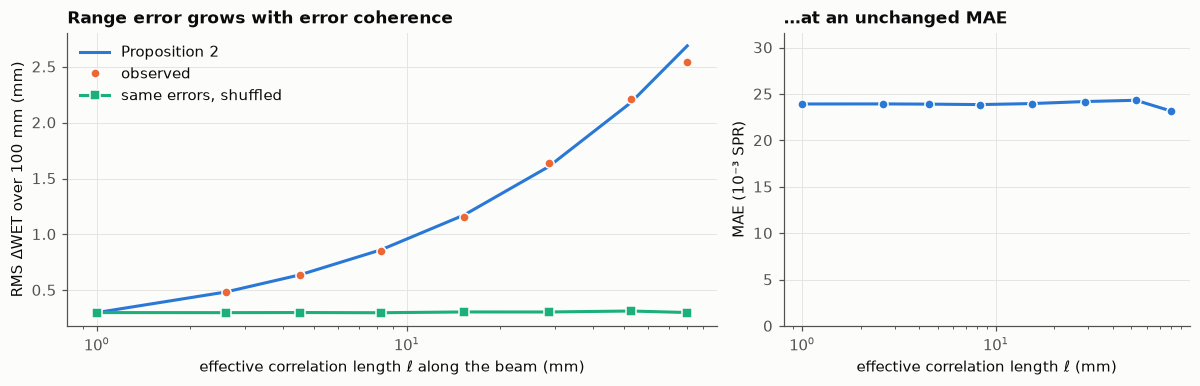

In [5]:
coherence = autocorrelation_experiment(CORRELATION_LENGTHS, rng(1))
biased = autocorrelation_experiment((0, 8), rng(11), mean=0.002)

relative_error = (coherence["rms_observed_mm"] / coherence["rms_predicted_mm"] - 1).abs()
record("1", "Proposition 2 predicts RMS ΔWET", f"max relative error {relative_error.max():.1%}", relative_error.max() < 0.08)
record("1", "Bias term L²μ² adds as predicted",
       f"max relative error {(biased['rms_observed_mm'] / biased['rms_predicted_mm'] - 1).abs().max():.1%}",
       (biased["rms_observed_mm"] / biased["rms_predicted_mm"] - 1).abs().max() < 0.08)
mae_spread = coherence["mae_spr"].std() / coherence["mae_spr"].mean()
record("1", "MAE unchanged across correlation lengths", f"coefficient of variation {mae_spread:.1%}", mae_spread < 0.05)
gain = coherence["rms_observed_mm"].max() / coherence["rms_observed_mm"].min()
record("1", "Corollary 2.1: same MAE, several-fold range error", f"RMS ratio {gain:.1f}×", gain > 5)
shuffled = (coherence["rms_permuted_mm"] / coherence["rms_predicted_mm"].iloc[0] - 1).abs().max()
record("1", "Shuffled errors behave as white noise", f"max deviation {shuffled:.1%}", shuffled < 0.05)

display(coherence.round(4))
plot_autocorrelation_law(coherence).savefig(FIGURE_DIR / "fig1_coherence.png", bbox_inches="tight")
plt.show()

## 2 · Spectral weighting

**Segments.** Plane-wave errors along the beam are summed over circular segments of length L. Proposition 3 states an
exact identity: the measured transfer must equal the Dirichlet kernel to machine precision, and errors that vary only
across the beam must pass unattenuated. Voxel-wise L2 and a forward-difference gradient loss are shown for comparison.

[PASS] Proposition 3: Parseval identity on random fields: max relative error 2.1e-16
[PASS] Measured transfer equals theory: max absolute gap 7.8e-16
[PASS] Errors varying across the beam pass unattenuated: transfer in [1.000000, 1.000000]


functional,gradient loss,"range, L = 10 mm","range, L = 60 mm","range, across beam",voxel L2
frequency,,,,,
0.003906,0.00015,0.99504,0.83189,1.0,1.0
0.015625,0.00241,0.92296,0.00439,1.0,1.0
0.062500,0.03806,0.22426,0.00365,1.0,1.0
0.250000,0.50000,0.02000,0.00000,1.0,1.0
0.500000,1.00000,0.00000,0.00000,1.0,1.0


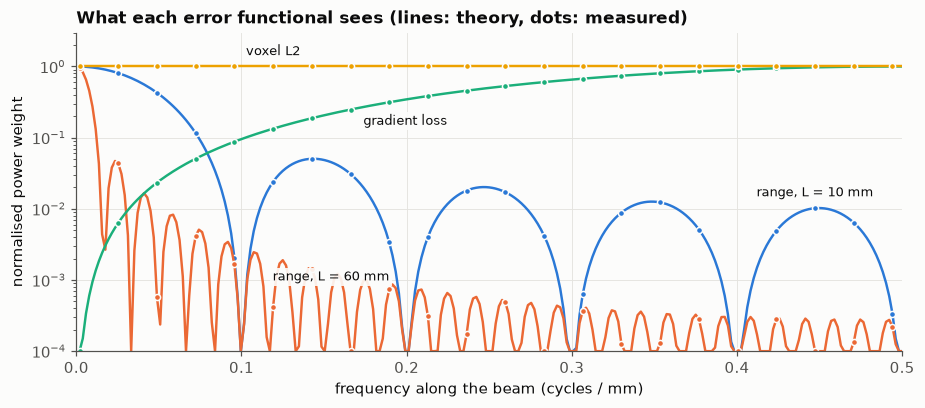

In [6]:
fields = gaussian_random_field((128, 48), 8.0, 4, rng(2))
parseval = max(
    abs(np.sum(sliding_segment_sums(field, length, axis=0) ** 2) - segment_energy_spectral(field, length, axis=0))
    / np.sum(sliding_segment_sums(field, length, axis=0) ** 2)
    for field in fields for length in (*SEGMENT_LENGTHS, 30)
)
record("2", "Proposition 3: Parseval identity on random fields", f"max relative error {parseval:.1e}", parseval < 1e-10)

transfer = transfer_experiment(SEGMENT_LENGTHS)
transfer_gap = float(np.max(np.abs(transfer["measured"] - transfer["theory"])))
record("2", "Measured transfer equals theory", f"max absolute gap {transfer_gap:.1e}", transfer_gap < 1e-10)
across = transfer[transfer["functional"] == "range, across beam"]["measured"]
record("2", "Errors varying across the beam pass unattenuated", f"transfer in [{across.min():.6f}, {across.max():.6f}]",
       np.allclose(across, 1.0))

landmarks = transfer[transfer["frequency"].isin([2 / 512, 8 / 512, 32 / 512, 128 / 512, 256 / 512])]
display(landmarks.pivot(index="frequency", columns="functional", values="theory").round(5))
plot_spectral_weights(transfer, LABELS).savefig(FIGURE_DIR / "fig2a_spectral_weights.png", bbox_inches="tight")
plt.show()

**All angles.** Windowed plane waves are projected with the differentiable projector over 180 angles. Proposition 3.1
predicts that the angle-summed range energy, relative to the voxel energy, decays as 1/|k|: a log-log slope of −1.

[PASS] Proposition 3.1: angle-summed energy ∝ 1/|k|: log-log slope -1.082


,frequency,projected_energy,voxel_energy,ratio
0,0.020,1.143462e+07,3890.528,2939.093
1,0.027,8.763168e+06,3875.325,2261.273
2,0.036,6.288932e+06,3880.365,1620.706
3,0.047,4.696121e+06,3888.114,1207.815
4,0.063,3.458679e+06,3885.484,890.154
5,0.084,2.533815e+06,3887.496,651.786
6,0.112,1.827016e+06,3887.477,469.975
7,0.150,1.289280e+06,3887.474,331.650


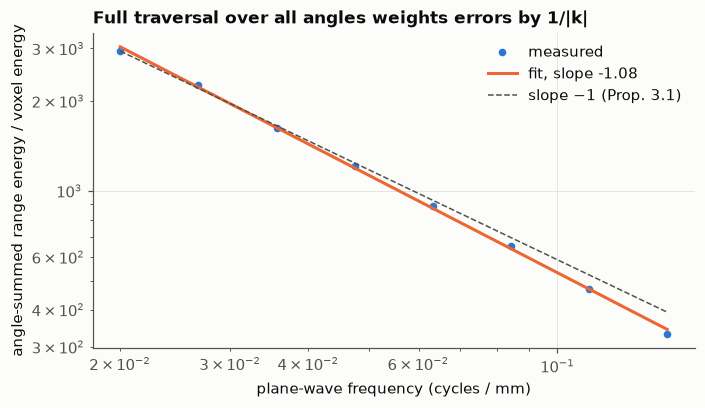

In [7]:
angles, slope = angle_energy_experiment(ANGLE_FREQUENCIES, rng(3))
record("2", "Proposition 3.1: angle-summed energy ∝ 1/|k|", f"log-log slope {slope:.3f}", abs(slope + 1) < 0.15)
display(angles.round(3))
plot_angle_energy(angles, slope).savefig(FIGURE_DIR / "fig2b_angle_energy.png", bbox_inches="tight")
plt.show()

## 3 · Bayes acts under range losses

Each voxel is soft tissue, or with probability pᵢ an alternative tissue (gas, or bone in the second scenario); pᵢ is a
smooth map of blobs peaking at 0.45, and a copula of correlation length 8 mm couples the classes. Three point estimates are
computed from the exact marginals: the HU mean (Bayes act of L2 in HU), the HU median (Bayes act of L1, in HU or SPR) and
the SPR mean g⁻¹(E[g(Y)]), the Bayes act of the squared range loss (Proposition 4). Segments run from depth 0 to 40, 80 and
120 mm, one per column.

For every ray the Monte Carlo risk over 3000 posterior draws is compared with the analytic decomposition
risk = bias² + variance, where the bias is computed from the exact marginals alone.

[PASS] Bayes act has zero range bias: max |mean bias| 2.9e-15 mm
[PASS] Bayes act has the lowest Monte Carlo range risk: 6/6 settings
[PASS] Risk = analytic bias² + variance: max relative gap 1.1%
[PASS] Proposition 5: L1 over-estimates SPR next to uncertain gas: mean bias 5.5 to 17.0 mm
[PASS] Proposition 5: L1 under-estimates SPR next to uncertain bone: mean bias -5.9 to -1.9 mm


mean_bias_mm  rms_mc_mm  rms_predicted_mm  excess_risk_mc_mm2  excess_risk_analytic_mm2
scenario estimator            depth_mm                                                                                         
bone     HU mean (L2 in HU)   40               0.437      2.110             2.105               0.241                     0.220
                              80               1.013      3.427             3.415               1.132                     1.050
                              120              1.537      4.247             4.229               2.580                     2.435
         HU median (L1)       40              -1.909      3.003             3.016               4.808                     4.885
                              80              -4.322      5.498             5.531              19.615                    19.983
                              120             -5.948      7.418             7.453              39.570                    40.102
         SPR mean (Bayes act) 40               0.000      2.052             2.052               0.000                     0.000
                              80               0.000      3.258             3.258               0.000                     0.000
                              120              0.000      3.931             3.931               0.000                     0.000
gas      HU mean (L2 in HU)   40               0.758      5.368             5.385               0.514                     0.716
                              80               1.800      8.619             8.658               2.642                     3.368
                              120              2.583     10.578            10.625               6.274                     7.311
         HU median (L1)       40               5.482      8.212             8.301              39.142                    40.624
                              80              12.404     15.225            15.387             160.147                   165.149
                              120             17.012     20.682            20.851             322.143                   329.190
         SPR mean (Bayes act) 40               0.000      5.320             5.318               0.000                     0.000
                              80               0.000      8.464             8.462               0.000                     0.000
                              120              0.000     10.277            10.275               0.000                     0.000

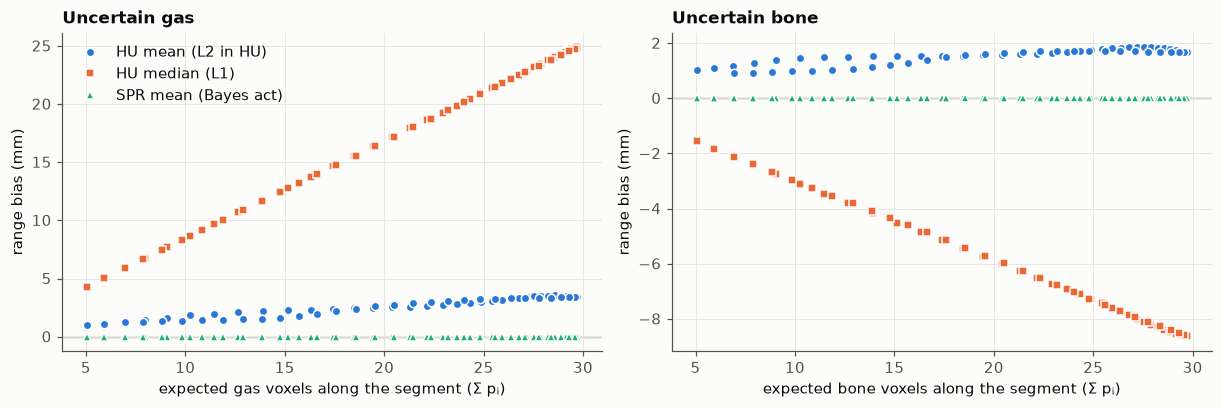

In [8]:
estimator_detail = pd.concat([estimator_experiment(hlut, scenario, rng(4 + i)) for i, scenario in enumerate(("gas", "bone"))])
estimator_summary = summarize_estimators(estimator_detail)

bayes = estimator_summary.xs("SPR mean (Bayes act)", level="estimator")
record("3", "Bayes act has zero range bias", f"max |mean bias| {bayes['mean_bias_mm'].abs().max():.1e} mm",
       bayes["mean_bias_mm"].abs().max() < 1e-9)
lowest = estimator_summary.groupby(["scenario", "depth_mm"])["rms_mc_mm"].idxmin().map(lambda index: index[1])
record("3", "Bayes act has the lowest Monte Carlo range risk", f"{(lowest == 'SPR mean (Bayes act)').sum()}/{len(lowest)} settings",
       (lowest == "SPR mean (Bayes act)").all())
decomposition = (estimator_summary["rms_mc_mm"] / estimator_summary["rms_predicted_mm"] - 1).abs().max()
record("3", "Risk = analytic bias² + variance", f"max relative gap {decomposition:.1%}", decomposition < 0.02)
median_bias = estimator_summary.xs("HU median (L1)", level="estimator")["mean_bias_mm"]
record("3", "Proposition 5: L1 over-estimates SPR next to uncertain gas",
       f"mean bias {median_bias.loc['gas'].min():.1f} to {median_bias.loc['gas'].max():.1f} mm", (median_bias.loc["gas"] > 0).all())
record("3", "Proposition 5: L1 under-estimates SPR next to uncertain bone",
       f"mean bias {median_bias.loc['bone'].min():.1f} to {median_bias.loc['bone'].max():.1f} mm", (median_bias.loc["bone"] < 0).all())

display(estimator_summary.round(3))
plot_estimator_bias(estimator_detail[estimator_detail["depth_mm"] == 120]).savefig(
    FIGURE_DIR / "fig3a_estimator_bias.png", bbox_inches="tight")
plt.show()

## 4 · Only the mean is consistent under projection

Six copies of the uniform law on a small HU multiset are coupled either cyclically (the joint mix of Theorem 6, whose sum
is constant) or independently (the law of the sum is enumerated exactly over 6⁶ outcomes). A functional is
projection-consistent when its value on the sum equals the sum of its voxel values under every coupling.

In [9]:
consistency = projection_consistency_table([-850.0, 40.0, 40.0, 40.0, 40.0, 700.0]).set_index("functional")
couplings = ["value on sum, cyclic coupling", "value on sum, independent coupling"]
matches = consistency[couplings].sub(consistency["sum of voxel values"], axis=0).abs().max(axis=1) < 1e-9
record("4", "Mean is additive under both couplings", f"max gap {consistency.loc['mean', couplings].sub(consistency.loc['mean', 'sum of voxel values']).abs().max():.1e}",
       matches["mean"])
record("4", "Median, quantile and expectiles are not", f"{(~matches.drop('mean')).sum()}/{len(matches) - 1} inconsistent",
       (~matches.drop("mean")).all())
display(consistency.round(2))

[PASS] Mean is additive under both couplings: max gap 0.0e+00
[PASS] Median, quantile and expectiles are not: 4/4 inconsistent


,sum of voxel values,"value on sum, cyclic coupling","value on sum, independent coupling"
functional,,,
mean,10.00,10.0,10.00
median,240.00,10.0,10.00
0.9-quantile,4200.00,10.0,1560.00
0.8-expectile,1406.67,10.0,606.40
0.2-expectile,-1693.33,10.0,-603.82


## 5 · Tails of range error need the joint law

The gas posterior is sampled with three copula correlation lengths. Voxel marginals, and therefore the Bayes act, are
identical in all three; only the dependence between voxels changes. The full-depth range error of the same point estimate
is then compared. The FZ0 score, minimised over a grid that does not contain the empirical values, must recover the
empirical VaR and ES of |ΔWET| within one grid step.

[PASS] Identical marginals across copulas: gas fraction range 0.004
[PASS] Proposition 7: same point estimate, different tail: VaR90 ratio 4.4×


[PASS] FZ0 score elicits (VaR, ES) of |ΔWET|: within one grid step


,correlation_length_px,alternative_fraction,mean_signed_mm,rms_mm,VaR90_mm,ES90_mm
0,0,0.242,0.011,3.661,6.031,7.583
1,4,0.241,-0.108,8.615,14.021,17.667
2,16,0.238,-0.337,18.064,26.311,36.907


,value
empirical VaR (mm),26.446
FZ argmin VaR (mm),26.526
empirical ES (mm),37.179
FZ argmin ES (mm),37.291
grid step VaR (mm),0.264
grid step ES (mm),0.372


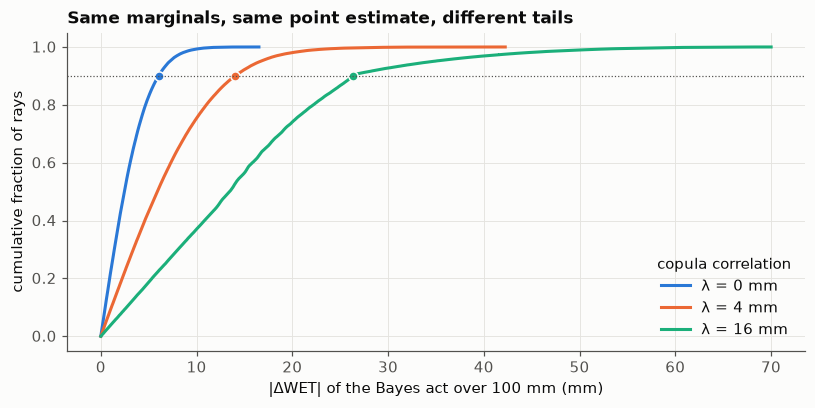

In [10]:
tails, tail_errors = tail_experiment(hlut, TAIL_CORRELATION_LENGTHS, rng(6))
fraction_gap = tails["alternative_fraction"].max() - tails["alternative_fraction"].min()
record("5", "Identical marginals across copulas", f"gas fraction range {fraction_gap:.3f}", fraction_gap < 0.01)
var_ratio = tails["VaR90_mm"].iloc[-1] / tails["VaR90_mm"].iloc[0]
record("5", "Proposition 7: same point estimate, different tail", f"VaR90 ratio {var_ratio:.1f}×", var_ratio > 2)

fz = fz_check(tail_errors[TAIL_CORRELATION_LENGTHS[-1]], rng=rng(7))
fz_ok = (abs(fz["FZ argmin VaR (mm)"] - fz["empirical VaR (mm)"]) <= 1.01 * fz["grid step VaR (mm)"]
         and abs(fz["FZ argmin ES (mm)"] - fz["empirical ES (mm)"]) <= 1.01 * fz["grid step ES (mm)"])
record("5", "FZ0 score elicits (VaR, ES) of |ΔWET|", "within one grid step", fz_ok)

display(tails.round(3))
display(pd.Series(fz, name="value").to_frame().round(3))
plot_tail_ecdf(tail_errors).savefig(FIGURE_DIR / "fig3b_tails.png", bbox_inches="tight")
plt.show()

## 6 · Evaluating generative predictions

Observations are drawn from the gas posterior with copula length 16 mm. Two ensemble forecasts with the exact voxel
marginals are scored: the correct model, and a model with independent voxels. Voxel-wise CRPS averages one-dimensional
scores per voxel; projected CRPS scores the law of each full-depth range integral. Differences are paired over
observations, with percentile bootstrap intervals.

In [11]:
crps = projected_crps_experiment(hlut, rng(8))
voxel = paired_difference(crps, "voxel CRPS, correct", "voxel CRPS, wrong dependence", rng(9))
projected = paired_difference(crps, "projected CRPS, correct", "projected CRPS, wrong dependence", rng(10))
record("6", "Voxel CRPS cannot tell the two forecasts apart",
       f"95% CI [{voxel['ci_low']:.4f}, {voxel['ci_high']:.4f}] contains 0", voxel["ci_low"] < 0 < voxel["ci_high"])
record("6", "Projected CRPS penalises the wrong dependence",
       f"95% CI [{projected['ci_low']:.2f}, {projected['ci_high']:.2f}] mm, {projected['relative to score']:.0%} worse",
       projected["ci_low"] > 0)
display(pd.DataFrame({"voxel CRPS (SPR)": voxel, "projected CRPS (mm)": projected}).T.round(4))

[PASS] Voxel CRPS cannot tell the two forecasts apart: 95% CI [-0.0023, 0.0017] contains 0
[PASS] Projected CRPS penalises the wrong dependence: 95% CI [2.04, 3.15] mm, 25% worse


,mean difference,ci_low,ci_high,relative to score
voxel CRPS (SPR),-0.0003,-0.0023,0.0017,-0.0017
projected CRPS (mm),2.6008,2.0400,3.1515,0.2505


## 7 · Verdicts

In [12]:
verdicts = pd.DataFrame(checks, columns=["section", "claim", "evidence", "passed"])
report = {
    "seed": SEED,
    "hlut_fingerprint": hlut.fingerprint(),
    "checks": verdicts.to_dict(orient="records"),
    "all_passed": bool(verdicts["passed"].all()),
}
(OUTPUT_DIR / "s2_report.json").write_text(json.dumps(report, indent=2))
estimator_summary.to_csv(OUTPUT_DIR / "estimator_summary.csv")
display(verdicts)
print(f"{verdicts['passed'].sum()}/{len(verdicts)} checks passed")

,section,claim,evidence,passed
0,1,"Propositions 1, 1′: exhaustive extremes equal ...",max gap 8.9e-16,True
1,1,Only comonotone arrangements attain the maximum,"20/20 trials, min gap to next value 0.009",True
2,1,Proposition 2 predicts RMS ΔWET,max relative error 5.5%,True
3,1,Bias term L²μ² adds as predicted,max relative error 0.9%,True
4,1,MAE unchanged across correlation lengths,coefficient of variation 1.4%,True
5,1,"Corollary 2.1: same MAE, several-fold range error",RMS ratio 8.5×,True
6,1,Shuffled errors behave as white noise,max deviation 4.6%,True
7,2,Proposition 3: Parseval identity on random fields,max relative error 2.1e-16,True
8,2,Measured transfer equals theory,max absolute gap 7.8e-16,True
9,2,Errors varying across the beam pass unattenuated,"transfer in [1.000000, 1.000000]",True


23/23 checks passed


## Consequences for S3–S5

These conclusions hold on the synthetic benchmark, where the posterior is known; on real data they are hypotheses to test.

1. **Regression target.** The squared-error regressor in SPR space is the Bayes act for mean squared range error. It
   becomes arm R3 and the reference every other arm must beat. An L1 loss, the default in sCT work, carries a
   signed range bias wherever the posterior is asymmetric, with a sign set by the tissue pair.
2. **Role of the range loss.** At the Bayes act no loss can reduce mean squared range error further, so the projected
   loss can only help through finite capacity (reallocating residual errors away from coherent, low-frequency patterns)
   and through the tails. Its claimed benefit must be measured on CVaR at matched MAE, against R3 and the per-tissue bias
   correction R4.
3. **Tails.** Range-error tails depend on dependence between voxels that no point estimate encodes. They require a
   joint model (the stochastic-interpolant flow) or a direct VaR/ES head trained with the FZ score.
4. **Evaluation.** Generative sCT models must be compared with projected CRPS; voxel-wise CRPS is blind to exactly the
   property that governs range.
5. **Diagnostic for S3.** On real sCTs, the shuffling controls and the spectral split of the error decide which
   mechanism dominates: coherent tissue-level biases (range loss and bias correction matter) or interface blur
   (largely invisible to range).